# 京都大学 2026 理系 第5問 — Julia + Wolfram Engine で解く

## 問題

$a$ は $0 < a < \pi$ を満たす実数とする。2 つの関数 $y = \sin(x + a)$ と $y = \sin(x - a)$ のグラフの，$-\dfrac{\pi}{2} \leqq x \leqq \dfrac{\pi}{2}$ の部分が囲む領域を $D_a$ とする。$x$ 軸のまわりに $D_a$ を 1 回転してできる立体の体積を求めよ。

## 0. 準備

共通の関数（表示 `tex`, `showtex`，変換 `to_expr`, `to_value`, `to_function` など）は `wolfram_common.jl` にまとめてあります。  
このノートブックと同じフォルダに置いて，`include` で読み込みます。

In [1]:
include("wolfram_common.jl")      # MathLink の読み込みと，共通の関数（表示・変換）
using Plots
using PlotsGRBackendFontJaEmoji   # グラフで日本語を使えるようにする

## 1. 2 つのグラフの共有点

$\sin(x+a) = \sin(x-a)$ を，$-\dfrac{\pi}{2} \leqq x \leqq \dfrac{\pi}{2}$，$0 < a < \pi$ の条件のもとで $x$ について解きます。

条件つきで `Solve` すると，解に「$0<a<\pi$ のとき」という但し書き（`ConditionalExpression`）が付くので，`Simplify[..., 0 < a < Pi]` で外します。

In [2]:
sol = weval(W`Simplify[Solve[Sin[x + a] == Sin[x - a] && -Pi/2 <= x <= Pi/2 && 0 < a < Pi, x, Reals], 0 < a < Pi]`)

W`List[List[Rule[x, Times[Rational[-1, 2], Pi]]], List[Rule[x, Times[Rational[1, 2], Pi]]]]`

解だけを取り出して，Julia の配列にします。

In [3]:
xs = to_value(weval(W`x /. $sol`))

2-element Vector{Float64}:
 -1.5707963267948966
  1.5707963267948966

共有点は区間の両端 $x = \pm\dfrac{\pi}{2}$ だけです。差を積の形に直すと理由が分かります。

In [4]:
d = weval(W`TrigFactor[Sin[x + a] - Sin[x - a]]`)

W`Times[2, Cos[x], Sin[a]]`

$\sin(x+a) - \sin(x-a) = 2\cos x \sin a$ で，$0 < a < \pi$ より $\sin a > 0$ なので，共有点は $\cos x = 0$ すなわち $x = \pm\dfrac{\pi}{2}$ のときに限ります。

また $-\dfrac{\pi}{2} < x < \dfrac{\pi}{2}$ では $\cos x > 0$ なので，つねに $\sin(x+a) > \sin(x-a)$ です。

## 2. $a$ を 1 つ固定してグラフをかく

Wolfram の式 $\sin(x+a)$，$\sin(x-a)$ を，`to_function` で $x$ と $a$ の Julia の関数にします。

In [5]:
f = to_function(W`Sin[x + a]`, :x, :a)      # 上側：y = sin(x + a)
g = to_function(W`Sin[x - a]`, :x, :a)      # 下側：y = sin(x - a)

#to_function##0 (generic function with 1 method)

例として $a = \dfrac{\pi}{3}$ に固定します（`a0` を変えれば他の値でもかけます）。$D_a$ は 2 つのグラフにはさまれた部分です。

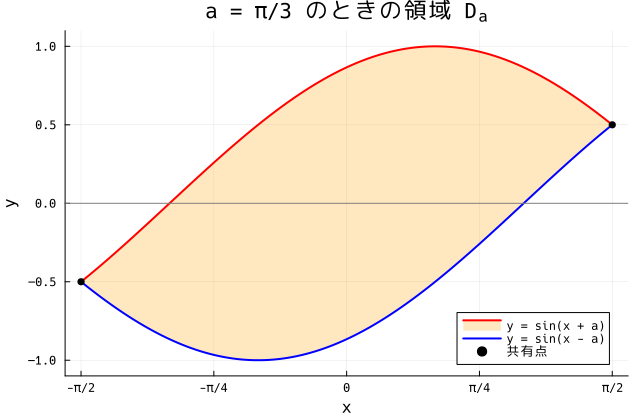

In [6]:
a0 = π / 3
x = range(-π/2, π/2; length=400)

plot(x, f.(x, a0); fillrange=g.(x, a0), fillalpha=0.25, fillcolor=:orange, lw=2, color=:red,
     label="y = sin(x + a)", xlabel="x", ylabel="y", title="a = π/3 のときの領域 Dₐ",
     xticks=([-π/2, -π/4, 0, π/4, π/2], ["-π/2", "-π/4", "0", "π/4", "π/2"]),
     ylims=(-1.1, 1.1), legend=:bottomright, size=(640, 420))
plot!(x, g.(x, a0); lw=2, color=:blue, label="y = sin(x - a)")
hline!([0]; color=:gray, label="")
scatter!(xs, f.(xs, a0); color=:black, label="共有点")

### いろいろな $a$ の値で

$a$ の値とタイトル用の文字列を受け取って $D_a$ をかく関数にまとめ，6 通りの $a$ を並べます。

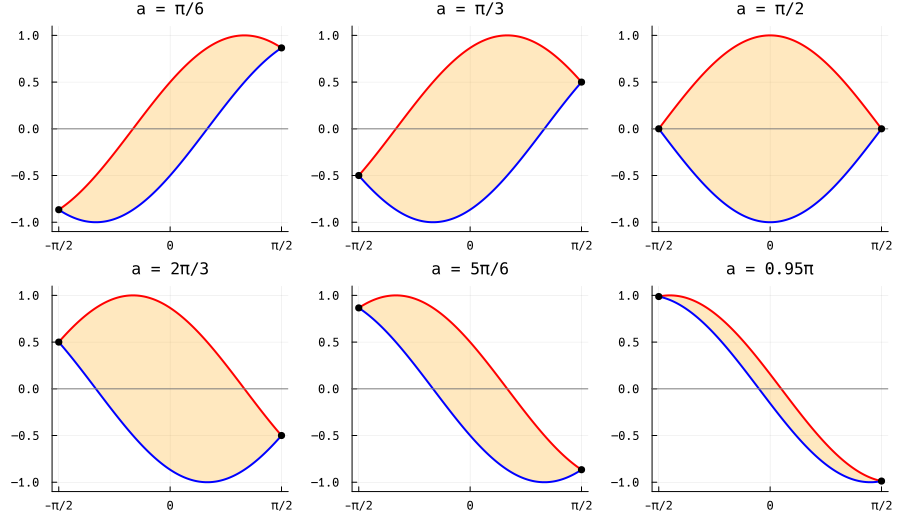

In [7]:
function plotD(a0, name)
    p = plot(x, f.(x, a0); fillrange=g.(x, a0), fillalpha=0.25, fillcolor=:orange, lw=2, color=:red,
             label="", title="a = $name", titlefontsize=11,
             xticks=([-π/2, 0, π/2], ["-π/2", "0", "π/2"]), ylims=(-1.1, 1.1))
    plot!(p, x, g.(x, a0); lw=2, color=:blue, label="")
    hline!(p, [0]; color=:gray, label="")
    scatter!(p, xs, f.(xs, a0); color=:black, label="")
end

as = [(π/6, "π/6"), (π/3, "π/3"), (π/2, "π/2"), (2π/3, "2π/3"), (5π/6, "5π/6"), (0.95π, "0.95π")]
plot([plotD(a0, name) for (a0, name) in as]...; layout=(2, 3), size=(900, 520))

赤が $y=\sin(x+a)$，青が $y=\sin(x-a)$ です。

- 共有点は $\left(-\dfrac{\pi}{2},\ -\cos a\right)$，$\left(\dfrac{\pi}{2},\ \cos a\right)$ なので，$a = \dfrac{\pi}{2}$ を境に両端の上下が入れかわります。
- $a = \dfrac{\pi}{2}$ のときは $y = \cos x$ と $y = -\cos x$ で，$x$ 軸に関して対称です。
- $a$ と $\pi - a$ の図は，左右を反転した形になっています。
- どの $a$ でも $D_a$ は $x$ 軸をまたいでいます。

## 3. $x$ 軸で上側に折り返す → 場合分けの $x$ を探す

$x$ 軸のまわりに回転するので，$x$ 軸より下の部分は上側に折り返して考えます。折り返したグラフは $y = |\sin(x+a)|$ と $y = |\sin(x-a)|$ です。

場合分けの境目になりそうな $x$ は，次の 3 種類です。

1. $\sin(x+a) = 0$（赤のグラフが $x$ 軸と交わる）
2. $\sin(x-a) = 0$（青のグラフが $x$ 軸と交わる）
3. $\sin(x+a) = -\sin(x-a)$（折り返したグラフどうしが交わる）

それぞれ $-\dfrac{\pi}{2} < x < \dfrac{\pi}{2}$，$0 < a < \pi$ の範囲で `Reduce` します。

In [8]:
# 論理記号を日本語にする
jtex(s) = replace(s, "\\lor" => "\\ \\ \\text{または}\\ \\ ", "\\land" => "\\ \\text{かつ}\\ ")

cond = "-Pi/2 < x < Pi/2 && 0 < a < Pi"
eqs  = ["Sin[x + a] == 0", "Sin[x - a] == 0", "Sin[x + a] == -Sin[x - a]"]

for eq in eqs
    r = weval(wparse("Reduce[$eq && $cond, x, Reals]"))
    showtex(heldtex(eq) * "\\iff " * jtex(tex(r)))
end

- 1, 2 の解は $a = \dfrac{\pi}{2}$ を境に式が変わります（$0 < a < \dfrac{\pi}{2}$ なら $x = \mp a$，$\dfrac{\pi}{2} < a < \pi$ なら $x = \pm(\pi - a)$）。
- 3 の解は $a \neq \dfrac{\pi}{2}$ なら $x = 0$ だけです。$a = \dfrac{\pi}{2}$ のときはすべての $x$ で成り立ちます（折り返すと 2 つのグラフが重なる）。

3 は和を積の形に直しても確かめられます。

In [9]:
weval(W`TrigFactor[Sin[x + a] + Sin[x - a]]`)

W`Times[2, Cos[a], Sin[x]]`

### 境目の $x$ を Julia の関数にする

`Solve` の結果（条件つきの解）を `Piecewise`（場合分けの式）に直し，$a$ の関数として Julia に持ってきます。

In [10]:
# 条件つきの解 ConditionalExpression[値, 条件] を {値, 条件} に直して Piecewise にする
border(eq) = weval(wparse("Piecewise[List @@@ (x /. Solve[$eq && $cond, x, Reals])]"))

b1, b2 = border(eqs[1]), border(eqs[2])
showtex("x_1 = " * tex(b1) * ",\\qquad x_2 = " * tex(b2))

x1 = to_function(b1, :a)      # sin(x + a) = 0 となる x
x2 = to_function(b2, :a)      # sin(x - a) = 0 となる x
x1(π/3), x2(π/3), x1(2π/3), x2(2π/3)

(-1.0471975511965976, 1.0471975511965976, 1.0471975511965979, -1.0471975511965979)

### 折り返したグラフ

$a = \dfrac{\pi}{3}$ のとき。回転させる部分（折り返したあとの $D_a$）を塗り，境目の $x$ に点線を引きます。

- 外側の半径：$|\sin(x+a)|$ と $|\sin(x-a)|$ の大きいほう
- 内側の半径：2 つのグラフが $x$ 軸の同じ側にあるときは小さいほう，反対側にあるときは $0$（$x$ 軸まで詰まっている）

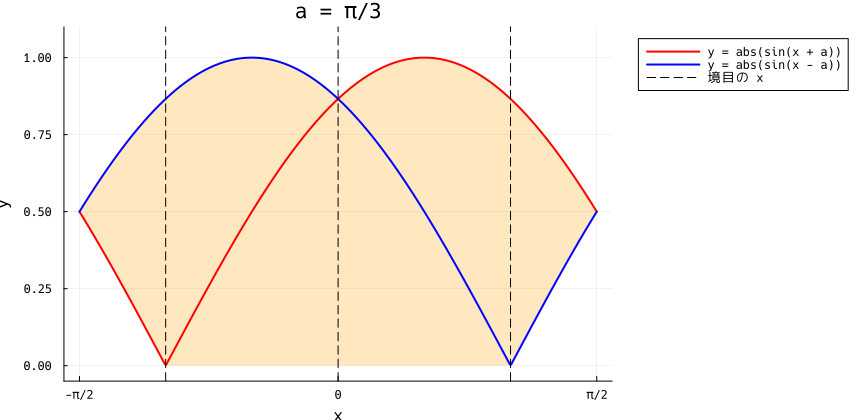

In [11]:
outer(x, a) = max(abs(f(x, a)), abs(g(x, a)))                               # 外側の半径
inner(x, a) = f(x, a) * g(x, a) > 0 ? min(abs(f(x, a)), abs(g(x, a))) : 0.0   # 内側の半径

function plotfold(a0, name; legend=false, kw...)
    p = plot(x, outer.(x, a0); fillrange=inner.(x, a0), fillalpha=0.25, fillcolor=:orange, lw=0, label="",
             title="a = $name", xticks=([-π/2, 0, π/2], ["-π/2", "0", "π/2"]), ylims=(-0.05, 1.1), legend=legend, kw...)
    plot!(p, x, abs.(f.(x, a0)); lw=2, color=:red,  label="y = abs(sin(x + a))")
    plot!(p, x, abs.(g.(x, a0)); lw=2, color=:blue, label="y = abs(sin(x - a))")
    vline!(p, [x1(a0), 0, x2(a0)]; color=:black, ls=:dash, label="境目の x")
end

plotfold(π/3, "π/3"; legend=:outertopright, size=(860, 420), xlabel="x", ylabel="y")

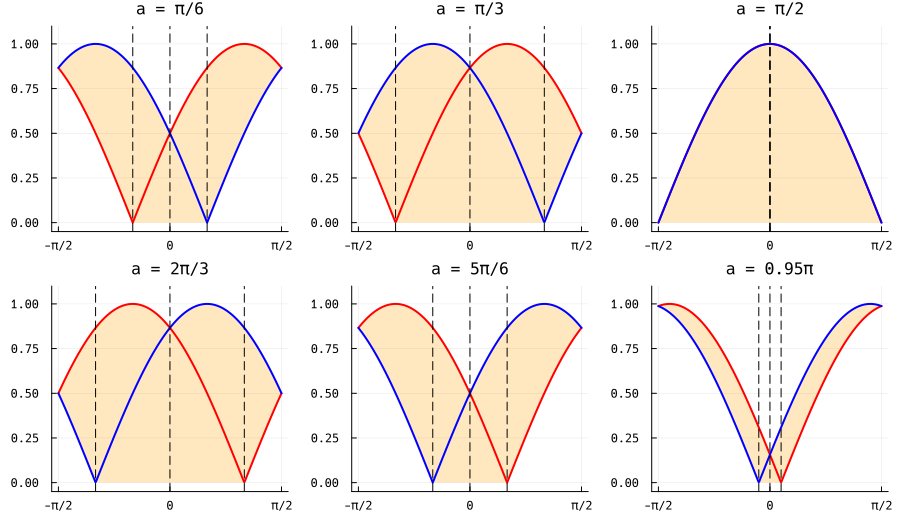

In [12]:
plot([plotfold(a0, name; titlefontsize=11) for (a0, name) in as]...; layout=(2, 3), size=(900, 520))

### 分かったこと

$0 < a < \dfrac{\pi}{2}$ のとき，境目は $x = -a,\ 0,\ a$ で，区間は 4 つに分かれます。

| 区間 | 外側の半径 | 内側の半径 |
|:--|:--|:--|
| $-\dfrac{\pi}{2} \leqq x \leqq -a$ | $\lvert\sin(x-a)\rvert$（青） | $\lvert\sin(x+a)\rvert$（赤） |
| $-a \leqq x \leqq 0$ | $\lvert\sin(x-a)\rvert$（青） | $0$ |
| $0 \leqq x \leqq a$ | $\lvert\sin(x+a)\rvert$（赤） | $0$ |
| $a \leqq x \leqq \dfrac{\pi}{2}$ | $\lvert\sin(x+a)\rvert$（赤） | $\lvert\sin(x-a)\rvert$（青） |

$\dfrac{\pi}{2} < a < \pi$ のときは，境目が $x = a - \pi,\ 0,\ \pi - a$ になり，赤と青の役割が入れかわります（$a$ を $\pi - a$ にした図の左右反転）。$a = \dfrac{\pi}{2}$ のときは折り返すと 2 つのグラフが重なり，場合分けは不要です（図の点線は $x = 0$ だけになっています）。

## 4. 回転体の体積

外側の半径を $R(x)$，内側の半径を $r(x)$ とすると，体積は

$$V = \pi\int_{-\pi/2}^{\pi/2}\left\{R(x)^2 - r(x)^2\right\}dx$$

です。3 節の表にしたがって，区間ごとに積分します。

### $0 < a < \dfrac{\pi}{2}$ のとき

境目は $x = -a,\ 0,\ a$。4 つの区間の「被積分関数，下端，上端」を並べて，`Integrate` します。

In [13]:
F2, G2 = "Sin[x + a]^2", "Sin[x - a]^2"        # 赤の 2 乗，青の 2 乗

# 区間ごとに積分して表示し，結果（Wolfram の式）の配列を返す
function integrals(parts)
    map(parts) do (h, lo, hi)
        cmd = "Integrate[$h, {x, $lo, $hi}]"
        r = weval(wparse("Simplify[$cmd]"))
        showtex(heldtex(cmd) * " = " * tex(r))
        r
    end
end

I1 = integrals([("$G2 - $F2", "-Pi/2", "-a"),      # 外：青，内：赤
                ("$G2",       "-a",    "0"),       # 外：青，内：0
                ("$F2",       "0",     "a"),       # 外：赤，内：0
                ("$F2 - $G2", "a",     "Pi/2")]);  # 外：赤，内：青

1 番目と 4 番目，2 番目と 3 番目がそれぞれ等しくなっています（折り返した図が $y$ 軸に関して対称だから）。4 つを足して $\pi$ をかけます。

In [14]:
V1 = weval(W"Simplify"(W"Times"(W"Pi", W"Plus"(I1...))))

W`Times[Pi, Plus[a, Times[3, Cos[a], Sin[a]]]]`

In [15]:
weval(W"TrigReduce"(V1))      # 2 倍角でまとめた形

W`Times[Rational[1, 2], Plus[Times[2, a, Pi], Times[3, Pi, Sin[Times[2, a]]]]]`

### $\dfrac{\pi}{2} < a < \pi$ のとき

境目は $x = a - \pi,\ 0,\ \pi - a$ で，赤と青の役割が入れかわります。

In [16]:
I2 = integrals([("$F2 - $G2", "-Pi/2",  "a - Pi"),   # 外：赤，内：青
                ("$F2",       "a - Pi", "0"),        # 外：赤，内：0
                ("$G2",       "0",      "Pi - a"),   # 外：青，内：0
                ("$G2 - $F2", "Pi - a", "Pi/2")]);   # 外：青，内：赤

In [17]:
V2 = weval(W"Simplify"(W"Times"(W"Pi", W"Plus"(I2...))))

W`Times[Pi, Plus[Times[-1, a], Pi, Times[-3, Cos[a], Sin[a]]]]`

$V_1$ の $a$ を $\pi - a$ に置きかえたものと一致することを確かめます（2 節で見た左右反転の対称性）。

In [18]:
weval(W"Simplify"(W"Equal"(V2, W"ReplaceAll"(V1, W"Rule"(W"a", W`Pi - a`)))))

W"True"

### まとめる

$a = \dfrac{\pi}{2}$ のときは $y = \pm\cos x$ を回転させるので $V = \pi\displaystyle\int_{-\pi/2}^{\pi/2}\cos^2 x\,dx = \dfrac{\pi^2}{2}$。これは $V_1$ に $a = \dfrac{\pi}{2}$ を代入した値と同じなので，$0 < a \leqq \dfrac{\pi}{2}$ にまとめられます。

In [19]:
Vmid  = weval(W`Pi Integrate[Cos[x]^2, {x, -Pi/2, Pi/2}]`)           # a = π/2 のときの体積
V1mid = weval(W"ReplaceAll"(V1, W"Rule"(W"a", W`Pi/2`)))             # V₁ に a = π/2 を代入
showtex(tex(Vmid) * ",\\qquad " * tex(V1mid))

In [20]:
Vw = weval(W"Piecewise"(W"List"(W"List"(V1, W`0 < a <= Pi/2`), W"List"(V2, W`Pi/2 < a < Pi`))))
showtex("V = " * tex(Vw))
V = to_function(Vw, :a);      # Julia の関数 V(a)

### 検算：Julia の数値積分と比べる

3 節で作った外側・内側の半径 `outer`, `inner`（場合分けを使わず，`max` / `min` で直接定義したもの）を QuadGK で数値積分し，上の式の値と比べます。

In [21]:
using QuadGK

# 境目で区間を分けて積分する（境目は小さい順に並べる）
Vnum(a) = π * quadgk(t -> outer(t, a)^2 - inner(t, a)^2, -π/2, sort([x1(a), 0, x2(a)])..., π/2)[1]

for (a0, name) in as
    println(rpad("a = $name", 12), "式の値 = ", round(V(a0); digits=10), "   数値積分 = ", round(Vnum(a0); digits=10))
end

a = π/6     式の値 = 5.7259826364   数値積分 = 5.7259826364
a = π/3     式の値 = 7.3709167032   数値積分 = 7.3709167032
a = π/2     式の値 = 4.9348022005   数値積分 = 4.9348022005
a = 2π/3    式の値 = 7.3709167032   数値積分 = 7.3709167032
a = 5π/6    式の値 = 5.7259826364   数値積分 = 5.7259826364
a = 0.95π   式の値 = 1.9496884991   数値積分 = 1.9496884991


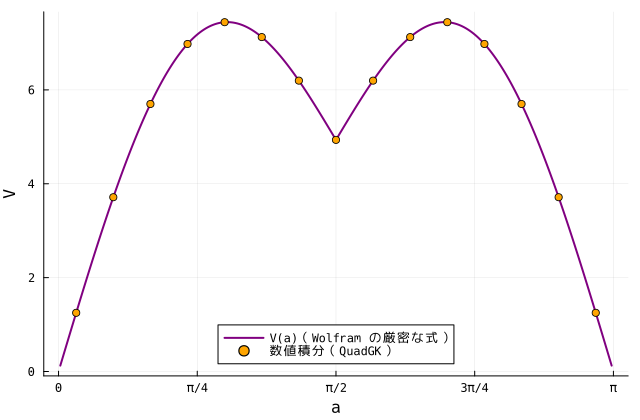

In [22]:
avals = range(0.01, π - 0.01; length=300)
plot(avals, V.(avals); lw=2, color=:purple, label="V(a)（Wolfram の厳密な式）", xlabel="a", ylabel="V",
     xticks=([0, π/4, π/2, 3π/4, π], ["0", "π/4", "π/2", "3π/4", "π"]), legend=:bottom, size=(640, 420))
apts = range(0.1, π - 0.1; length=15)
scatter!(apts, Vnum.(apts); color=:orange, label="数値積分（QuadGK）")

## 答え

$$V = \begin{cases} \pi\left(a + \dfrac{3}{2}\sin 2a\right) & \left(0 < a \leqq \dfrac{\pi}{2}\right) \\[2ex] \pi\left(\pi - a - \dfrac{3}{2}\sin 2a\right) & \left(\dfrac{\pi}{2} < a < \pi\right) \end{cases}$$

（$3\sin a\cos a = \dfrac{3}{2}\sin 2a$ で書き直しています。）